<a href="https://colab.research.google.com/github/abhiii04-25/Deep-Learning/blob/main/Simple_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense

In [5]:
sentences = [
    "I love this product",
    "This movie made me smile",
    "Service was friendly and quick",
    "Today felt bright and happy",
    "This is the best day",
    "Absolutely fantastic experience",
    "I enjoyed every single moment",
    "Great job, well done",
    "The food tasted delicious",
    "Totally recommend to everyone",
    "Very satisfied with results",
    "This worked better than expected",
    "Amazing quality and value",
    "Such a pleasant surprise",
    "I feel positive about this",
    "I hate this product",
    "This movie bored me",
    "Service was rude and slow",
    "Today was cold and lonely",
    "This is the worst day",
    "Terrible experience overall",
    "I regret buying this",
    "Very disappointed with results",
    "The food tasted awful",
    "Do not recommend this",
    "It broke after one use",
    "Not worth the money",
    "Utterly frustrating and annoying",
    "I feel negative about this",
    "Such a waste of time",
]

labels = [1] * 15 + [0] * 15
labels = np.array(labels)


In [7]:
vocab_size=2000
tok=Tokenizer(num_words=vocab_size,oov_token='<OOV>')
tok.fit_on_texts(sentences)
seq=tok.texts_to_sequences(sentences)
maxlen=max(len(s) for s in seq)
X=pad_sequences(seq,maxlen=maxlen,padding='post')
y=labels

In [8]:
maxlen

5

In [9]:
X[0]

array([ 3, 26,  2,  7,  0], dtype=int32)

In [12]:
embed_dim=16
rnn_units=8

In [15]:
inp=Input(shape=(maxlen,),dtype='int32',name='input')
x=Embedding(input_dim=vocab_size,output_dim=embed_dim, mask_zero=True,name='embed')(inp)
# Corrected the typo 'rturn_seqeunces' to 'return_sequences' and unpacked the outputs
x_last, state = SimpleRNN(units=rnn_units, return_sequences=False, return_state=True, name='simple_rnn')(x)
out=Dense(1,activation='sigmoid',name='out')(x_last)
model=Model(inputs=inp,outputs=out)
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 5)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed (Embedding)   │ (None, 5, 16)     │     32,000 │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 5)         │          0 │ input[0][0]       │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ [(None, 8),       │        200 │ embed[0][0],      │
│ (SimpleRNN)         │ (None, 8)]        │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ out (Dense)         │ (None, 1)         │          9 │ simple_rnn[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 32,209 (125.82 KB)

 Trainable params: 32,209 (125.82 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.fit(X,y,epochs=25,batch_size=8,verbose=1)

Epoch 1/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.4667 - loss: 0.6944
Epoch 2/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6000 - loss: 0.6823
Epoch 3/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7667 - loss: 0.6722
Epoch 4/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8000 - loss: 0.6619
Epoch 5/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8333 - loss: 0.6518
Epoch 6/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8333 - loss: 0.6406
Epoch 7/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9333 - loss: 0.6285
Epoch 8/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9333 - loss: 0.6153
Epoch 9/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9333 - loss: 0.6018
Epoch 10/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9333 - loss: 0.5866
Epoch 11/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9333 - loss: 0.5702
Epoch 12/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9333 - loss: 0.5539
E

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create an intermediate model to extract step-by-step hidden states (return_sequences=True) and the final state

# Instantiate the new RNN layer with return_sequences=True
rnn_seq_layer = SimpleRNN(
    units=rnn_units,
    return_sequences=True,
    return_state=True,
    name='simple_rnn_seq'
)

# Define intermediate model pipeline
int_inp = model.input
int_embed = model.get_layer('embed')(int_inp)
int_seq_out, int_state_out = rnn_seq_layer(int_embed)

intermediate_model = Model(inputs=int_inp, outputs=[int_seq_out, int_state_out])

# Copy trained weights explicitly from the original model layer
original_weights = model.get_layer('simple_rnn').get_weights()
rnn_seq_layer.set_weights(original_weights)

In [25]:
# 2. Choose a sample sentence to visualize
sample_idx = 0
sample_input = X[sample_idx:sample_idx+1]
sample_text = sentences[sample_idx]

# Pointing to the successfully created intermediate_model_demo
seq_out, state_out = intermediate_model_demo.predict(sample_input)

print(f"Sample Sentence: '{sample_text}'")
print(f"Tokenized sequence: {sample_input[0]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Sample Sentence: 'I love this product'
Tokenized sequence: [ 3 26  2  7  0]


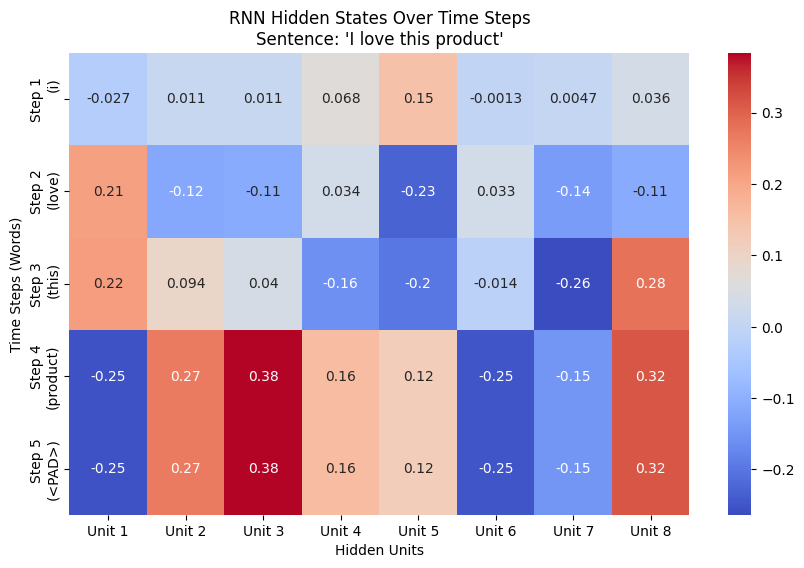

In [28]:
# 3. Plot the intermediate hidden states across all time steps
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure seq_out is available in the current namespace
if 'seq_out' in globals():
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        seq_out[0],
        annot=True,
        cmap='coolwarm',
        xticklabels=[f'Unit {i+1}' for i in range(rnn_units)],
        yticklabels=[f'Step {i+1}\n({tok.index_word.get(token, "<PAD>")})' for i, token in enumerate(sample_input[0])]
    )
    plt.title(f"RNN Hidden States Over Time Steps\nSentence: '{sample_text}'")
    plt.xlabel("Hidden Units")
    plt.ylabel("Time Steps (Words)")
    plt.show()
else:
    print("Error: 'seq_out' is still not found in your environment. Please run the consolidated cell (5a18878b) first to generate the variables!")

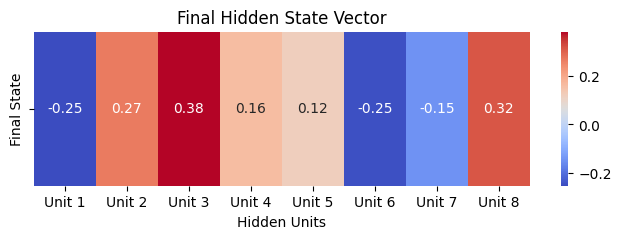

In [29]:
# 4. Plot the final state compared to the last sequence step
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure state_out is available in the current namespace
if 'state_out' in globals():
    plt.figure(figsize=(8, 2))
    sns.heatmap(
        state_out,
        annot=True,
        cmap='coolwarm',
        xticklabels=[f'Unit {i+1}' for i in range(rnn_units)],
        yticklabels=['Final State']
    )
    plt.title("Final Hidden State Vector")
    plt.xlabel("Hidden Units")
    plt.show()
else:
    print("Error: 'state_out' is still not found in your environment. Please run the consolidated cell (5a18878b) first!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step


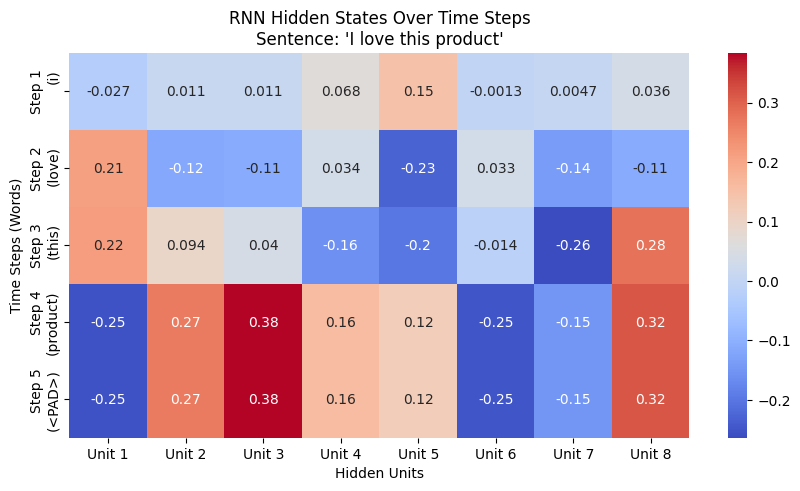

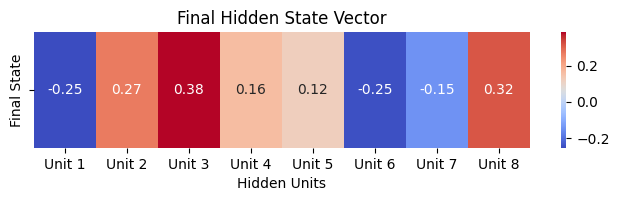

In [24]:
# Consolidated Cell to define intermediate model, make predictions, and visualize
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define intermediate model and load weights
rnn_seq_layer = SimpleRNN(
    units=rnn_units,
    return_sequences=True,
    return_state=True,
    name='simple_rnn_seq_demo'
)

int_inp = model.input
int_embed = model.get_layer('embed')(int_inp)
int_seq_out, int_state_out = rnn_seq_layer(int_embed)

intermediate_model_demo = Model(inputs=int_inp, outputs=[int_seq_out, int_state_out])
intermediate_model_demo.compile()

original_weights = model.get_layer('simple_rnn').get_weights()
rnn_seq_layer.set_weights(original_weights)

# 2. Extract states on a sample input
sample_idx = 0
sample_input = X[sample_idx:sample_idx+1]
sample_text = sentences[sample_idx]
seq_out, state_out = intermediate_model_demo.predict(sample_input)

# 3. Visualize Intermediate Hidden States
plt.figure(figsize=(10, 5))
sns.heatmap(
    seq_out[0],
    annot=True,
    cmap='coolwarm',
    xticklabels=[f'Unit {i+1}' for i in range(rnn_units)],
    yticklabels=[f'Step {i+1}\n({tok.index_word.get(token, "<PAD>")})' for i, token in enumerate(sample_input[0])]
)
plt.title(f"RNN Hidden States Over Time Steps\nSentence: '{sample_text}'")
plt.xlabel("Hidden Units")
plt.ylabel("Time Steps (Words)")
plt.show()

# 4. Visualize Final Hidden State Vector
plt.figure(figsize=(8, 1.5))
sns.heatmap(
    state_out,
    annot=True,
    cmap='coolwarm',
    xticklabels=[f'Unit {i+1}' for i in range(rnn_units)],
    yticklabels=['Final State']
)
plt.title("Final Hidden State Vector")
plt.xlabel("Hidden Units")
plt.show()

Mean Hidden State Vector:
[-0.02190933  0.10477746  0.1417705   0.05287297 -0.00871507 -0.09586579
 -0.13887066  0.16733365]


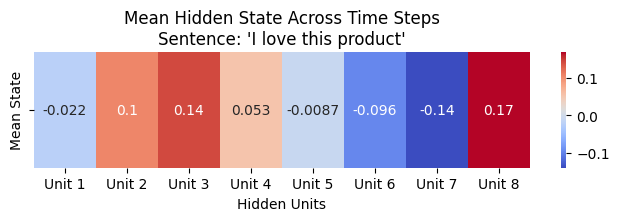

In [27]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the mean hidden state across all time steps (axis 1)
# seq_out shape is (1, maxlen, rnn_units)
mean_hidden_state = np.mean(seq_out[0], axis=0, keepdims=True)

# Display the numerical values
print("Mean Hidden State Vector:")
print(mean_hidden_state[0])

# Visualize the mean hidden state vector
plt.figure(figsize=(8, 1.5))
sns.heatmap(
    mean_hidden_state,
    annot=True,
    cmap='coolwarm',
    xticklabels=[f'Unit {i+1}' for i in range(rnn_units)],
    yticklabels=['Mean State']
)
plt.title(f"Mean Hidden State Across Time Steps\nSentence: '{sample_text}'")
plt.xlabel("Hidden Units")
plt.show()